# Pipeline Completo de Análise e Validação de Curvas de Juros
### `bz-pricing` vs. Dados Oficiais B3 e Banco Central do Brasil (BCB)

Este notebook consolida e valida a construção das estruturas a termo do mercado financeiro brasileiro e internacional:
1. **Curvas Pré-Fixadas Onshore:** DI x PRE e SELIC x PRE;
2. **Curvas Regulatórias e Derivadas:** TBF x PRE, TR x PRE, TBF x LTN e TR x LTN;
3. **Curvas de Inflação:** Cupom Sujo de IPCA (DIC), Cupom Limpo DAP (DPL) e Cupom Sujo de IGP-M (DIM);
4. **Curvas de Moedas e Câmbio:** Cupom Cambial DDI (DOL / DOC), Forwards PTX, EUR e JPY;
5. **Curvas Internacionais Offshore:** SOFR (SFR e ZUS), ESTR (EST e ZEU) e F-TIIE (TIE e ZMX);
6. **Curvas de Ações e Índices:** Ibovespa (INP), IBrX-50 (BRP), Small Caps (SML), Custo de Carrego (CYI) e Futuros de Ações.


In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
import os
import datetime
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from bcb import sgs

from bz_pricing.curves.builder import B3CurveBuilder
from bz_pricing.data.loaders import B3DataLoader
from bz_pricing.data.scrapers import B3Scraper
from bz_pricing.curves.manager import CurveManager

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (14, 7)

In [3]:
from importlib import metadata
from pandas.tseries.offsets import BDay
# Configuração Base
base_date = datetime.date(2026, 10, 30)
data_dir = os.path.join('../dados/b3')
loader = B3DataLoader(data_dir)
builder = B3CurveBuilder()
# Instancia o CurveManager com allow_download=True para baixar dados oficiais da B3/BCB automaticamente
manager = CurveManager(loader, builder, allow_download=True)
scraper = B3Scraper(output_dir=data_dir)

# Garante o download dos arquivos de negociação (SPRD) e cadastro (IN) da data base
date_str = base_date.strftime('%Y%m%d')
if not os.path.exists(os.path.join(data_dir, f'BVBG_SPRD_{date_str}.csv')):
    print(f'Baixando Negociação B3 (SPRD) da data base: {date_str}')
    scraper.download_bvbg_187_01(base_date)
if not os.path.exists(os.path.join(data_dir, f'BVBG_IN_{date_str}.csv')):
    print(f'Baixando Cadastro de Instrumentos B3 (IN) da data base: {date_str}')
    scraper.download_instruments(base_date)

# Baixa os 5 dias úteis anteriores caso não existam (necessário para apuração do fator médio da TBF)
for i in range(1, 6):
    d = (pd.to_datetime(base_date) - BDay(i)).date()
    d_str = d.strftime('%Y%m%d')
    if not os.path.exists(os.path.join(data_dir, f'BVBG_SPRD_{d_str}.csv')):
        print(f'Baixando TBF histórico (SPRD): {d_str}')
        scraper.download_bvbg_187_01(d)
    if not os.path.exists(os.path.join(data_dir, f'BVBG_IN_{d_str}.csv')):
        print(f'Baixando Cadastro de Instrumentos (IN) histórico: {d_str}')
        scraper.download_instruments(d)


## 1. Coleta do Vértice 1 (CDI e Selic Diária BCB SGS)
O primeiro vértice ($DU = 1$) das curvas pré-fixadas é ancorado nas taxas *overnight*:
- **CDI (Série SGS 12):** Taxa over do mercado interbancário;
- **Selic Diária (Série SGS 11):** Taxa apurada pelo BCB em operações compromissadas com títulos públicos federais, anualizada exponencialmente em base 252.


In [4]:
# CDI (Série 12) e Selic Diária (Série 11) via Banco Central do Brasil
# sgs.get recebe start e end date como strings no formato '%Y-%m-%d'
start_str = (base_date - datetime.timedelta(days=7)).strftime('%Y-%m-%d')
end_str = base_date.strftime('%Y-%m-%d')
df_bcb = sgs.get({'CDI': 12, 'SELIC': 11}, start=start_str, end=end_str)
if not df_bcb.empty:
    cdi_d = float(df_bcb['CDI'].dropna().iloc[-1]) / 100.0
    selic_d = float(df_bcb['SELIC'].dropna().iloc[-1]) / 100.0
    v1_cdi = round(((1.0 + cdi_d) ** 252.0 - 1.0) * 10000.0) / 10000.0
    v1_selic = round(((1.0 + selic_d) ** 252.0 - 1.0) * 10000.0) / 10000.0
else:
    raise RuntimeError(f'Não foi possível obter CDI/SELIC via SGS do BCB para a data {base_date}.')

print(f'Vértice 1 CDI (SGS 12): {v1_cdi*100:.2f}% a.a.')
print(f'Vértice 1 SELIC (SGS 11): {v1_selic*100:.2f}% a.a.')

# Instanciando o CurveManager para orquestrar as curvas onshore e offshore
manager = CurveManager(loader=loader, builder=builder, allow_download=True)


Vértice 1 CDI (SGS 12): 13.65% a.a.
Vértice 1 SELIC (SGS 11): 13.65% a.a.


## 2. Curva DI x PRE (Contratos Futuros de DI1)
Construção via **Flat Forward 252** confrontando a curva `bz-pricing` com os dados diários oficiais de taxas referenciais da B3 (`taxas_PRE_*.csv`).


In [5]:
# Extrai contratos DI1
df_di1 = loader.get_curve_instruments(base_date, asst="DI1")

# Constrói a curva Padrão B3 (Exponential Interpolator)
curve_pre_std = manager.get_curve("PRE", base_date)

# Constrói a curva com Suavização Spline
# Suavização pode ser feita no manager (hardcoded para teste) ou chamada manualmente
curve_pre_smooth = manager.builder.build_from_config(df_di1, "PRE", base_date, v1_rate=v1_cdi, smoothing=0.0001)

# Baixa a curva oficial da B3 para comparação
b3_pre_path = scraper.download_taxas_referenciais(data = base_date, produto = "PRE")

# Le os dados baixados
df_b3_pre = pd.read_csv(b3_pre_path, sep = ';')

Arquivo de taxas referenciais (PRE - 20261030) já existe em: ../dados/b3\taxas_PRE_20261030.csv. Use force=True para baixar novamente.


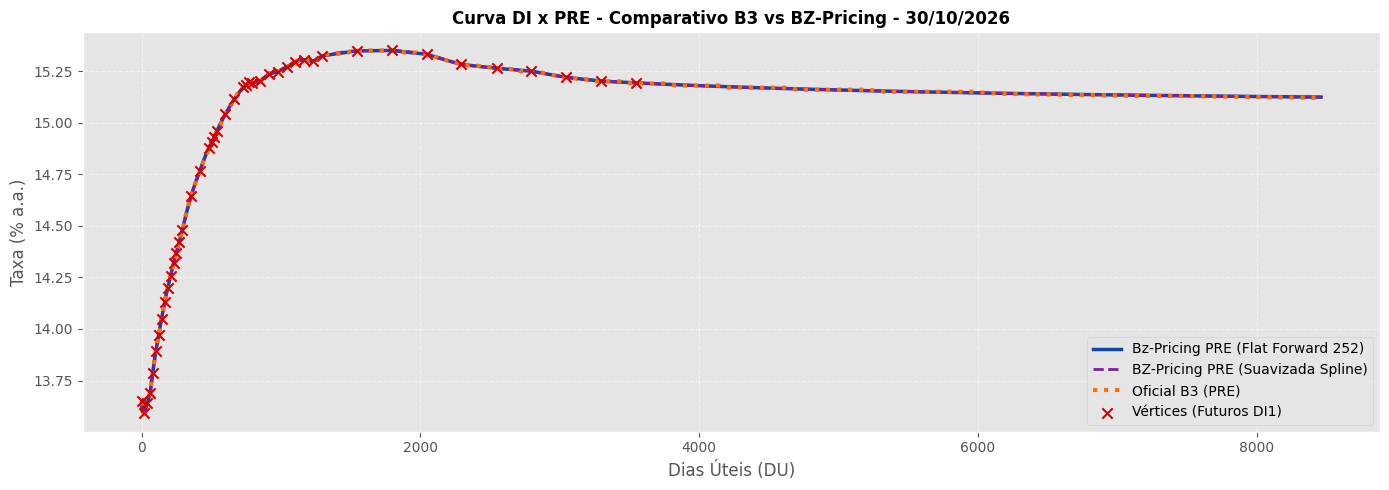

In [6]:
du_grid = np.arange(1, 8464, 2)
rates_std = [curve_pre_std.get_rate(float(du)) * 100 for du in du_grid]
rates_smooth = [curve_pre_smooth.get_rate(float(du)) * 100 for du in du_grid]

plt.figure(figsize=(14, 5))
plt.plot(du_grid, rates_std, label='Bz-Pricing PRE (Flat Forward 252)', color='#0D47A1', linewidth=2.5)
plt.plot(du_grid, rates_smooth, label='BZ-Pricing PRE (Suavizada Spline)', color='#7B1FA2', linestyle='--', linewidth=2.0)

if df_b3_pre is not None and not df_b3_pre.empty:
    plt.plot(df_b3_pre['day252'], df_b3_pre['rate'], label='Oficial B3 (PRE)', color='#FF6F00', linewidth=3.0, linestyle=':')

# Pontos dos Contratos Futuros Originais
cal = builder.cal
df_di1['DU'] = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_di1['XprtnDt']]
df_di1_valid = df_di1[df_di1['DU'] > 0]
plt.scatter(df_di1_valid['DU'], df_di1_valid['AdjstdQtTax'], color='#D50000', marker='x', s=55, label='Vértices (Futuros DI1)', zorder=5)

plt.title(f'Curva DI x PRE - Comparativo B3 vs BZ-Pricing - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


## 3. Curva Selic x PRE (Contratos Futuros de OC1)
Construção via **Flat Forward 252** sobre os contratos OC1, confrontando com `taxas_SLP_*.csv` da B3.


In [7]:
df_oc1 = loader.get_curve_instruments(base_date, asst="OC1")

curve_selic = builder.build_from_config(df_oc1, "SELIC_PRE", base_date, v1_rate=v1_selic)

# Taxas Referenciais da B3
b3_selic_path = scraper.download_taxas_referenciais(data=base_date, produto="SLP")

# Le os dados baixados
df_b3_selic = pd.read_csv(b3_selic_path, sep = ';')

Arquivo de taxas referenciais (SLP - 20261030) já existe em: ../dados/b3\taxas_SLP_20261030.csv. Use force=True para baixar novamente.


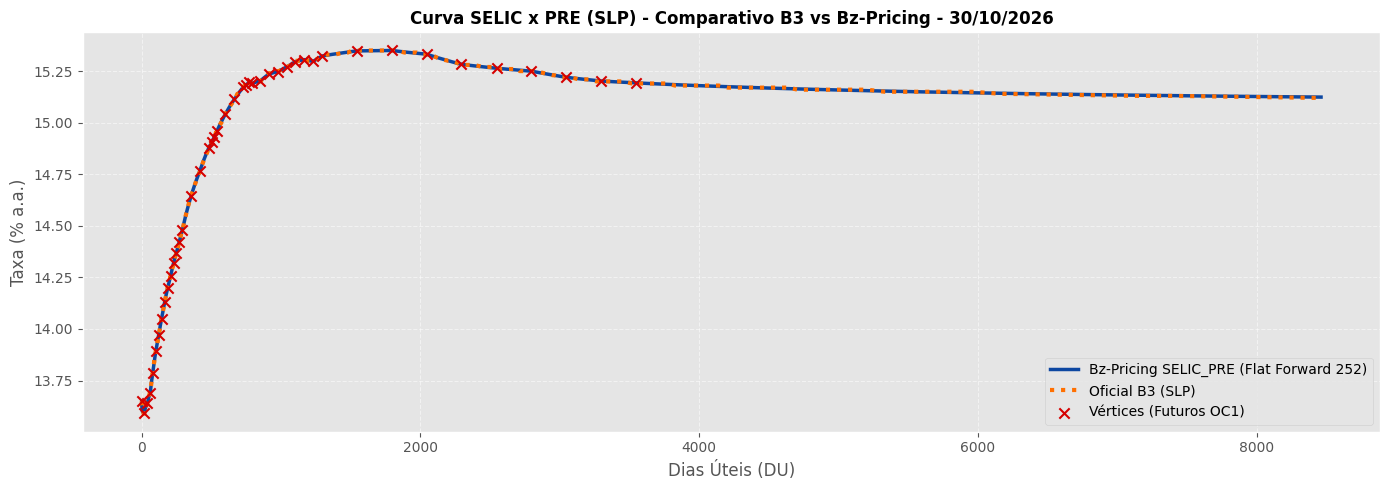

In [8]:
du_grid_selic = np.arange(1, 8464, 2)
rates_selic = [curve_selic.get_rate(float(du)) * 100 for du in du_grid_selic]

plt.figure(figsize=(14, 5))
plt.plot(du_grid_selic, rates_selic, label='Bz-Pricing SELIC_PRE (Flat Forward 252)', color='#0D47A1', linewidth=2.5)

if df_b3_selic is not None and not df_b3_selic.empty:
    plt.plot(df_b3_selic['day252'], df_b3_selic['rate'], label='Oficial B3 (SLP)', color='#FF6F00', linewidth=3.0, linestyle=':')

# Pontos Originais
df_oc1['DU'] = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_oc1['XprtnDt']]
df_oc1_valid = df_oc1[df_oc1['DU'] > 0]
plt.scatter(df_oc1_valid['DU'], df_oc1_valid['AdjstdQtTax'], color='#D50000', marker='x', s=55, label='Vértices (Futuros OC1)', zorder=5)

plt.title(f'Curva SELIC x PRE (SLP) - Comparativo B3 vs Bz-Pricing - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


## 4. Curvas Derivadas: TBF x PRE, TR x PRE e Títulos Públicos (LTN)
Especificação metodológica das curvas derivadas:
- Apuração do fator médio histórico da TBF ($MediaTBF_{fator,t}$);
- Aplicação da tabela escalonada de redutores da TR;
- Construção sobre base de contratos DI e títulos públicos do Tesouro Nacional (LTN da ANBIMA MS).


Baixando arquivo MS ANBIMA: https://www.anbima.com.br/informacoes/merc-sec/arqs/ms261023.txt


Baixando arquivo MS ANBIMA: https://www.anbima.com.br/informacoes/merc-sec/arqs/ms261023.txt
Arquivo de taxas referenciais (TFP - 20261030) já existe em: ../dados/b3\taxas_TFP_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (TP - 20261030) já existe em: ../dados/b3\taxas_TP_20261030.csv. Use force=True para baixar novamente.


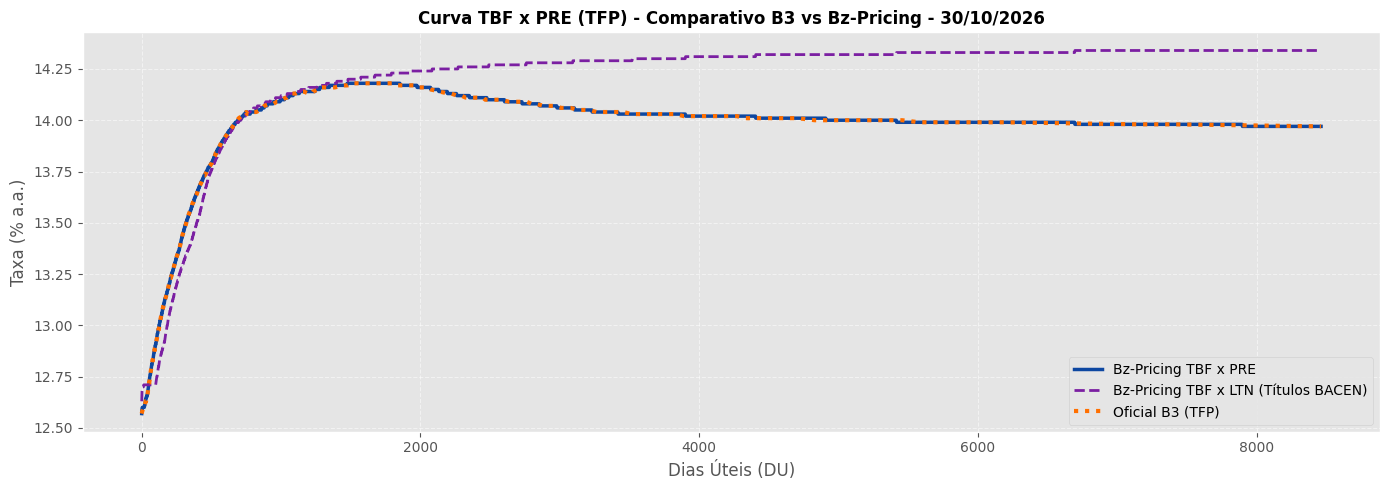

In [9]:
# Curva PRE Base e Curvas TBF e TR via CurveManager
curve_pre = manager.get_curve('PRE', base_date)
curve_tbf_pre = manager.get_curve('TBF_PRE', base_date)
curve_tr_pre = manager.get_curve('TR_PRE', base_date)

# Curva baseada em títulos públicos (LTN)
curve_ltn = manager.get_curve('LTN', base_date)
curve_tbf_ltn = manager.get_curve('TBF_LTN', base_date)
curve_tr_ltn = manager.get_curve('TR_LTN', base_date)

# Dados Oficiais B3
b3_tfp_path = scraper.download_taxas_referenciais(data=base_date, produto='TFP')
df_b3_tfp = pd.read_csv(b3_tfp_path, sep=';')
b3_tp_path = scraper.download_taxas_referenciais(data=base_date, produto='TP')
df_b3_tp = pd.read_csv(b3_tp_path, sep=';')

du_grid = np.arange(1, 8464, 2)

# ---- Gráfico TBF (TFP) ----
plt.figure(figsize=(14, 5))
plt.plot(du_grid, [curve_tbf_pre.get_rate(float(du)) * 100 for du in du_grid], label='Bz-Pricing TBF x PRE', color='#0D47A1', linewidth=2.5)
plt.plot(du_grid, [curve_tbf_ltn.get_rate(float(du)) * 100 for du in du_grid], label='Bz-Pricing TBF x LTN (Títulos BACEN)', color='#7B1FA2', linestyle='--', linewidth=2.0)
if df_b3_tfp is not None and not df_b3_tfp.empty:
    plt.plot(df_b3_tfp['day252'], df_b3_tfp['rate'], label='Oficial B3 (TFP)', color='#FF6F00', linestyle=':', linewidth=3.0)
plt.title(f'Curva TBF x PRE (TFP) - Comparativo B3 vs Bz-Pricing - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


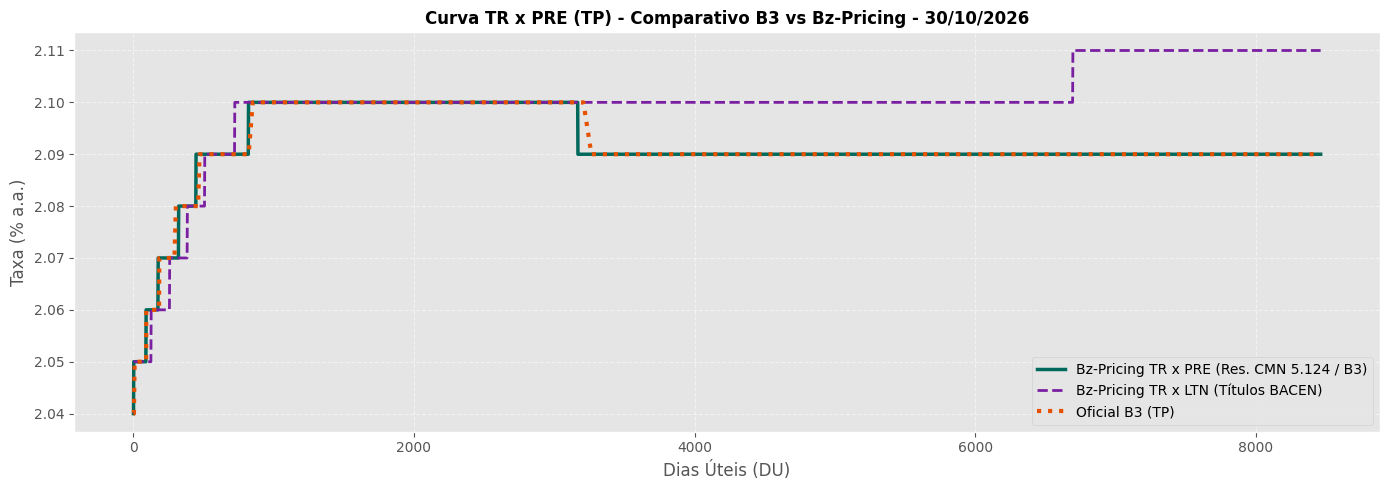

In [10]:
# ---- Gráfico TR (TP) ----
plt.figure(figsize=(14, 5))
plt.plot(du_grid, [curve_tr_pre.get_rate(float(du)) * 100 for du in du_grid], label='Bz-Pricing TR x PRE (Res. CMN 5.124 / B3)', color='#00695C', linewidth=2.5)
plt.plot(du_grid, [curve_tr_ltn.get_rate(float(du)) * 100 for du in du_grid], label='Bz-Pricing TR x LTN (Títulos BACEN)', color='#7B1FA2', linestyle='--', linewidth=2.0)
if df_b3_tp is not None and not df_b3_tp.empty:
    plt.plot(df_b3_tp['day252'], df_b3_tp['rate'], label='Oficial B3 (TP)', color='#E65100', linestyle=':', linewidth=3.0)
plt.title(f'Curva TR x PRE (TP) - Comparativo B3 vs Bz-Pricing - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


## 5. Curvas de Inflação Implícita: IPCA (DIC e DAP) e IGP-M (DIM)
- **DIC:** Cupom Sujo de IPCA com amortização de deflação ultracurta ($DU \le 6$) e ancoragem nas NTN-Bs;
- **DAP / DPL:** Cupom Limpo de IPCA oriundo de contratos futuros DAP (vencimento todo dia 15);
- **DIM:** Cupom Sujo de IGP-M com pro-rata de liquidação da FGV no curto prazo e **Extrapolação Flat Fim** no longo prazo.


Arquivo de taxas referenciais (DIC - 20261030) já existe em: ../dados/b3\taxas_DIC_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (DPL - 20261030) já existe em: ../dados/b3\taxas_DPL_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (DIM - 20261030) já existe em: ../dados/b3\taxas_DIM_20261030.csv. Use force=True para baixar novamente.


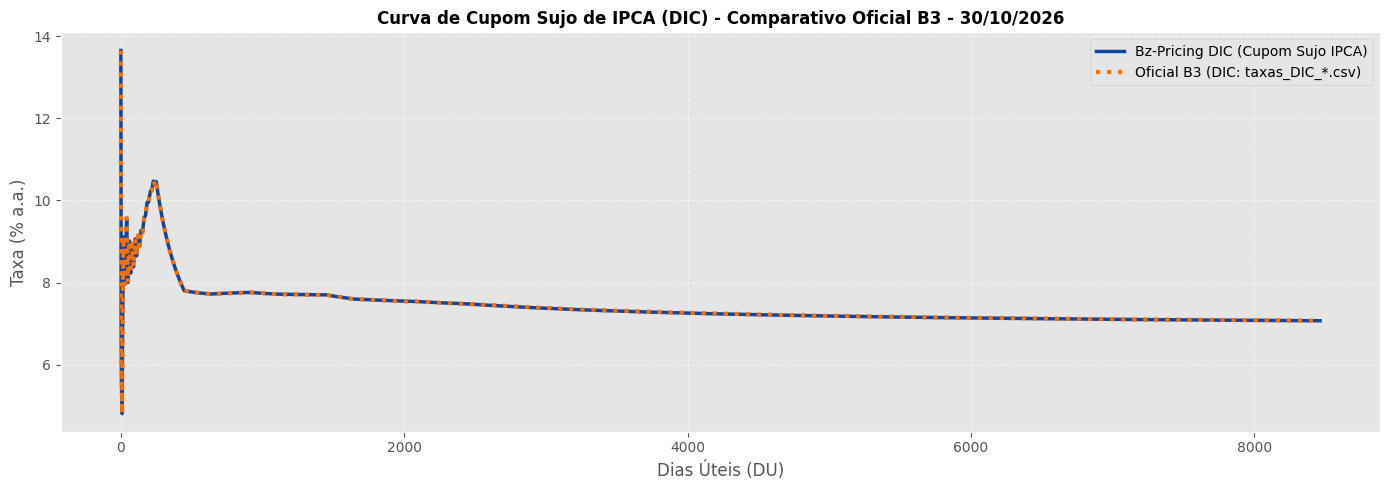

In [11]:
# DIC e DIM representam as curvas de Cupom Sujo de IPCA e IGP-M
# DPL representa o Cupom Limpo de IPCA oriundo de contratos DAP e NTN-B
b3_dic_path = scraper.download_taxas_referenciais('DIC', base_date)
b3_dpl_path = scraper.download_taxas_referenciais('DPL', base_date)
b3_dim_path = scraper.download_taxas_referenciais('DIM', base_date)

df_b3_dic = pd.read_csv(b3_dic_path, sep=';')
df_b3_dpl = pd.read_csv(b3_dpl_path, sep=';')
df_b3_dim = pd.read_csv(b3_dim_path, sep=';')

curve_dic = manager.get_curve('DIC', base_date)
curve_dpl = manager.get_curve('DPL', base_date)
curve_dim = manager.get_curve('DIM', base_date)

du_grid = np.arange(1, 8464, 1)

# ---- Gráfico DIC: Cython DIC vs Oficial B3 (DIC) ----
plt.figure(figsize=(14, 5))
plt.plot(du_grid, [curve_dic.get_rate(float(du)) * 100 for du in du_grid], label='Bz-Pricing DIC (Cupom Sujo IPCA)', color='#0D47A1', linewidth=2.5)
if df_b3_dic is not None and not df_b3_dic.empty:
    plt.plot(df_b3_dic['day252'], df_b3_dic['rate'], label='Oficial B3 (DIC: taxas_DIC_*.csv)', color='#FF6F00', linewidth=3.0, linestyle=':')
plt.title(f'Curva de Cupom Sujo de IPCA (DIC) - Comparativo Oficial B3 - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


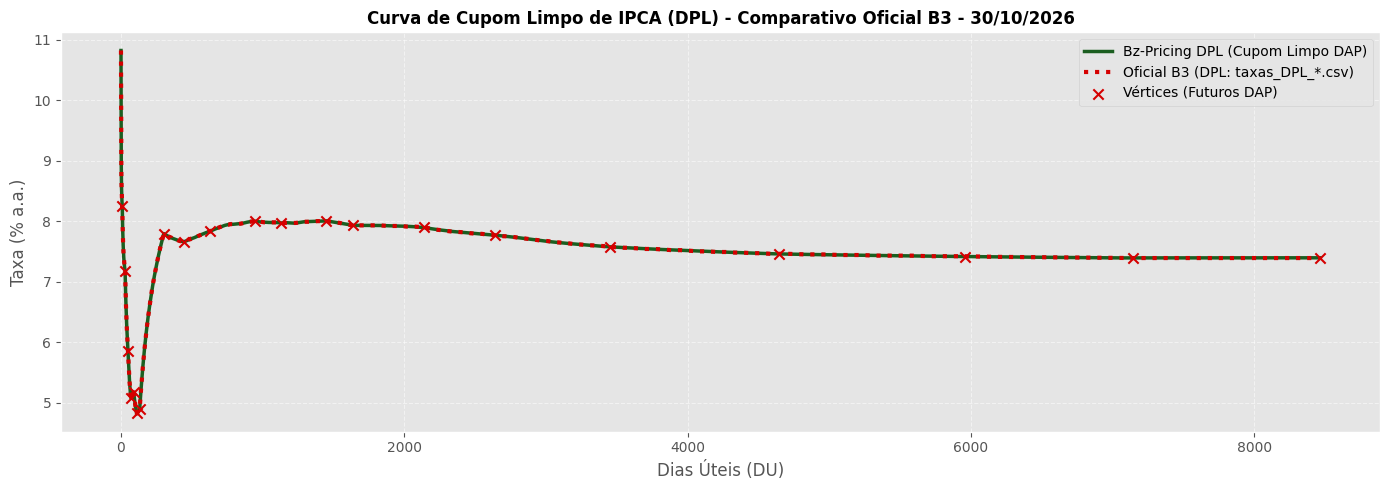

In [12]:
# ---- Gráfico DPL: Cython DPL vs Oficial B3 (DPL) ----
plt.figure(figsize=(14, 5))
plt.plot(du_grid, [curve_dpl.get_rate(float(du)) * 100 for du in du_grid], label='Bz-Pricing DPL (Cupom Limpo DAP)', color='#1B5E20', linewidth=2.5)
if df_b3_dpl is not None and not df_b3_dpl.empty:
    plt.plot(df_b3_dpl['day252'], df_b3_dpl['rate'], label='Oficial B3 (DPL: taxas_DPL_*.csv)', color='#D50000', linewidth=3.0, linestyle=':')

# Vértices dos Contratos Futuros de DAP (Base de Interpolação)
df_dap = loader.get_curve_instruments(base_date, asst='DAP')
if df_dap is not None and not df_dap.empty:
    cal = builder.cal
    df_dap['DU'] = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_dap['XprtnDt']]
    df_dap_valid = df_dap[df_dap['DU'] > 0]
    plt.scatter(df_dap_valid['DU'], df_dap_valid['AdjstdQtTax'], color='#D50000', marker='x', s=55, label='Vértices (Futuros DAP)', zorder=5)

plt.title(f'Curva de Cupom Limpo de IPCA (DPL) - Comparativo Oficial B3 - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


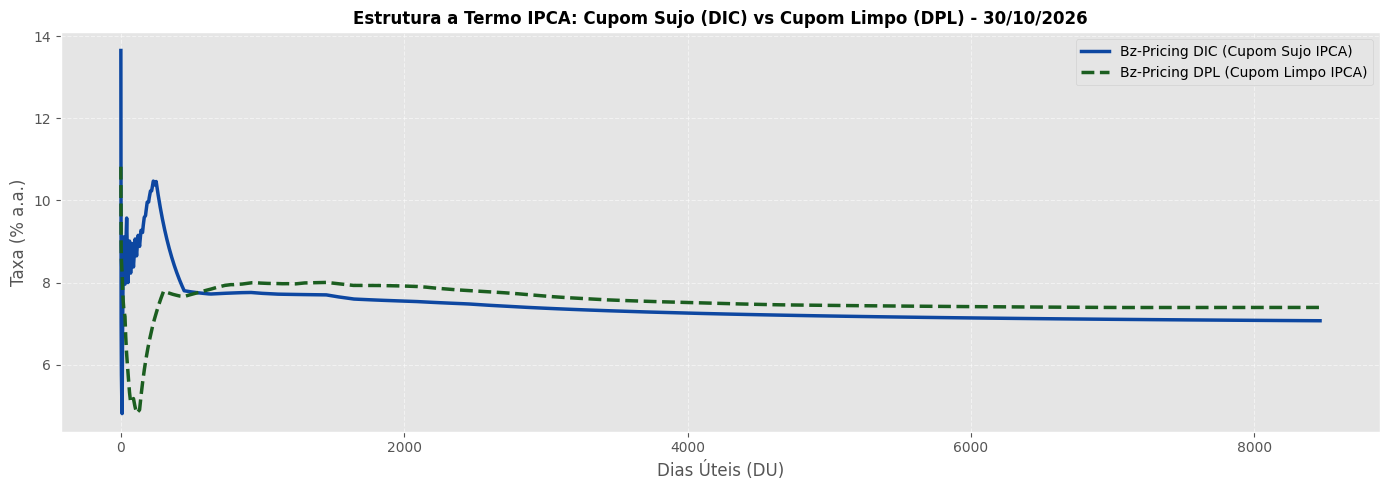

In [13]:
# ---- Comparativo Estrutural: DIC (Sujo) vs DPL (Limpo) ----
plt.figure(figsize=(14, 5))
plt.plot(du_grid, [curve_dic.get_rate(float(du)) * 100 for du in du_grid], label='Bz-Pricing DIC (Cupom Sujo IPCA)', color='#0D47A1', linewidth=2.5)
plt.plot(du_grid, [curve_dpl.get_rate(float(du)) * 100 for du in du_grid], label='Bz-Pricing DPL (Cupom Limpo IPCA)', color='#1B5E20', linestyle='--', linewidth=2.5)
plt.title(f'Estrutura a Termo IPCA: Cupom Sujo (DIC) vs Cupom Limpo (DPL) - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


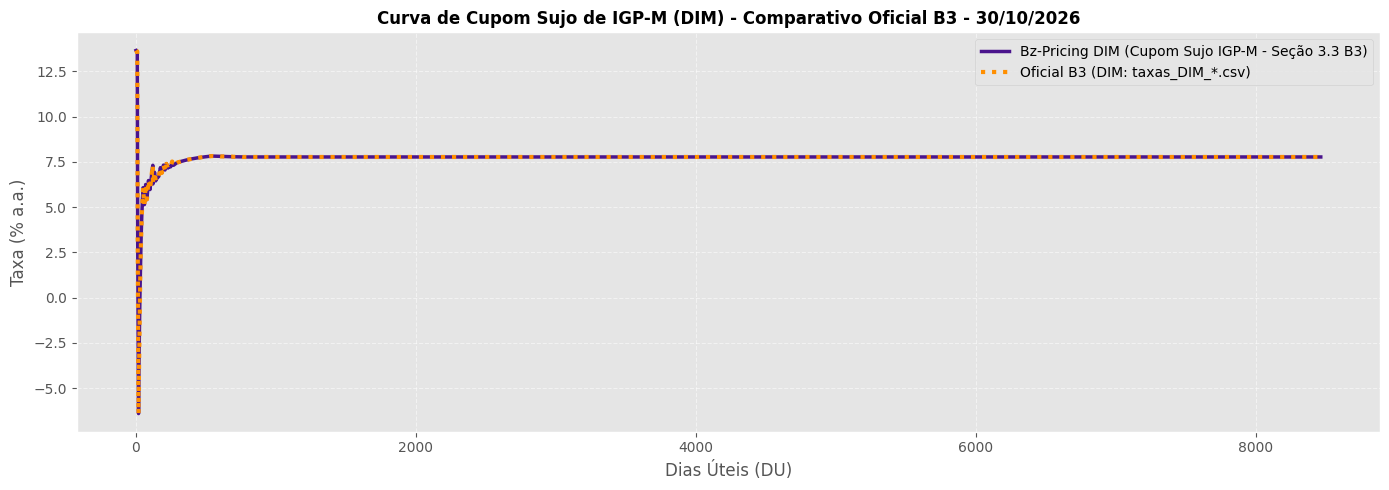

In [14]:
# ---- Gráfico DIM (Cupom Sujo IGP-M) ----
plt.figure(figsize=(14, 5))
plt.plot(du_grid, [curve_dim.get_rate(float(du)) * 100 for du in du_grid], label='Bz-Pricing DIM (Cupom Sujo IGP-M)', color='#4A148C', linewidth=2.5)
if df_b3_dim is not None and not df_b3_dim.empty:
    plt.plot(df_b3_dim['day252'], df_b3_dim['rate'], label='Oficial B3 (DIM: taxas_DIM_*.csv)', color='#FF8F00', linewidth=3.0, linestyle=':')
plt.title(f'Curva de Cupom Sujo de IGP-M (DIM) - Comparativo Oficial B3 - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## 6. Curvas de Moedas, Cupons Cambiais e Spreads
Comparações ponto a ponto das curvas desenvolvidas em Cython contra as curvas oficiais publicadas pela B3:
- **DOL:** Cupom Cambial Sujo baseado nos ajustes dos contratos futuros de DDI (parte de **-73.16%** em DU 1 até **+20.25%** em DU 8463);
- **DOC:** Cupom Cambial Limpo da B3 com pool de informantes (inicia em **+141.79%** em DU 1);
- **EUC:** Cupom de Euro calculado analiticamente pela fórmula oficial:
  $$EUC_n = \left[ \left(1 + DOC_n \times \frac{DC_n}{36000}\right) \times \left(1 + SDE_n \times \frac{DC_n}{36000}\right) - 1 \right] \times \frac{36000}{DC_n}$$
  (parte rigorosamente em **+140.00%** em DU 1 e converge suavemente para 3.10% em DU 20 e 5.0% no longo prazo);
- **SDE:** Spread Libor Euro x Dólar ($TEU - TUS$) oficial da B3 (varia de **-1.76%** a **-1.55%**);
- **Forward Cambial PTX, EUR e JPY:** Taxas a termo projetadas e confrontadas com as curvas oficiais de taxas referenciais da B3.


Arquivo de taxas referenciais (DOL - 20261030) já existe em: ../dados/b3\taxas_DOL_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (DOC - 20261030) já existe em: ../dados/b3\taxas_DOC_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (EUC - 20261030) já existe em: ../dados/b3\taxas_EUC_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (SDE - 20261030) já existe em: ../dados/b3\taxas_SDE_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (PTX - 20261030) já existe em: ../dados/b3\taxas_PTX_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (EUR - 20261030) já existe em: ../dados/b3\taxas_EUR_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (JPY - 20261030) já existe em: ../dados/b3\taxas_JPY_20261030.csv. Use force=True para baixar novamente.


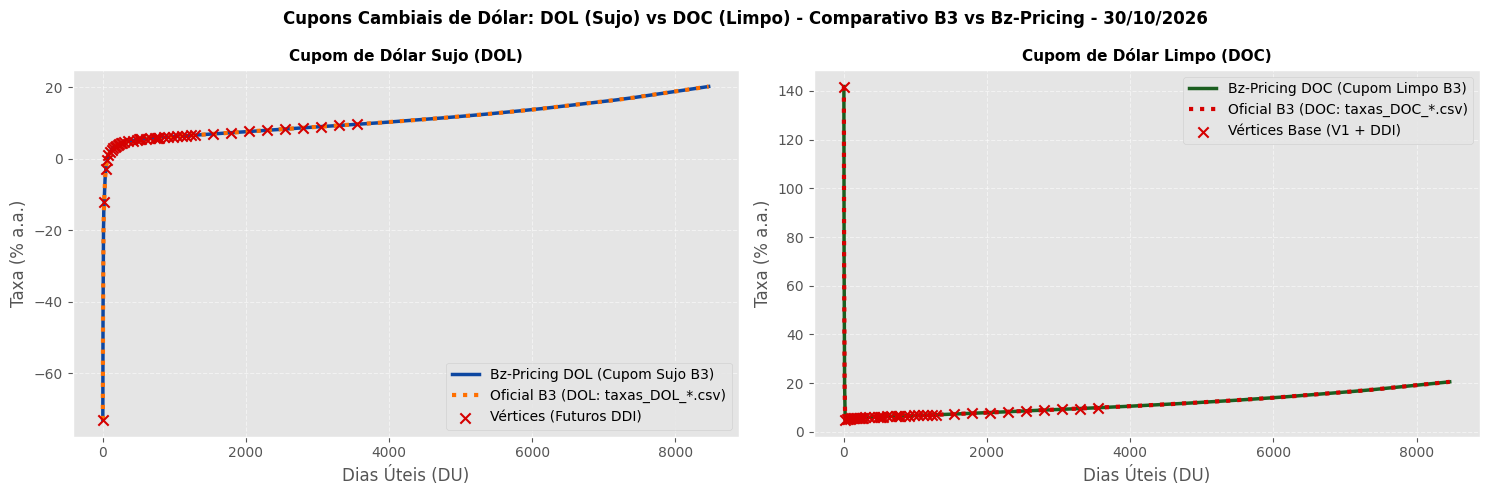

In [15]:
# Carrega curvas via CurveManager
curve_dol = manager.get_curve('DOL', base_date)
curve_doc = manager.get_curve('DOC', base_date)
curve_euc = manager.get_curve('EUC', base_date)
curve_sde = manager.get_curve('SDE', base_date)
curve_ptx = manager.get_curve('PTX', base_date)
curve_eur = manager.get_curve('EUR', base_date)
curve_jpy = manager.get_curve('JPY', base_date)

# Carrega curvas oficiais da B3 baixadas para a data
df_b3_dol = pd.read_csv(scraper.download_taxas_referenciais(produto='DOL', data=base_date), sep=';')
df_b3_doc = pd.read_csv(scraper.download_taxas_referenciais(produto='DOC', data=base_date), sep=';')
df_b3_euc = pd.read_csv(scraper.download_taxas_referenciais(produto='EUC', data=base_date), sep=';')
df_b3_sde = pd.read_csv(scraper.download_taxas_referenciais(produto='SDE', data=base_date), sep=';')
df_b3_ptx = pd.read_csv(scraper.download_taxas_referenciais(produto='PTX', data=base_date), sep=';')
df_b3_eur = pd.read_csv(scraper.download_taxas_referenciais(produto='EUR', data=base_date), sep=';')
df_b3_jpy = pd.read_csv(scraper.download_taxas_referenciais(produto='JPY', data=base_date), sep=';')

# Contratos Futuros de DDI (Base de Interpolação para DOL e DOC)
cal = builder.cal
df_ddi = loader.get_curve_instruments(base_date, asst='DDI')
df_ddi['DU'] = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_ddi['XprtnDt']]
df_ddi_valid = df_ddi[df_ddi['DU'] > 0]

# Gráficos Cupons Cambiais de Dólar (DOL Sujo e DOC Limpo em Subplots Separados)
fig, (ax_dol, ax_doc) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot Cupom Sujo de Dólar (DOL)
ax_dol.plot(df_b3_dol['day252'], [curve_dol.get_rate(row['day252'], row['day360']) * 100 for _, row in df_b3_dol.iterrows()], 
            label='Bz-Pricing DOL (Cupom Sujo B3)', color='#0D47A1', linewidth=2.5)
ax_dol.plot(df_b3_dol['day252'], df_b3_dol['rate'], ':', 
            label='Oficial B3 (DOL: taxas_DOL_*.csv)', color='#FF6F00', linewidth=3.0)
ax_dol.scatter(df_ddi_valid['DU'], df_ddi_valid['AdjstdQtTax'], color='#D50000', marker='x', s=55, label='Vértices (Futuros DDI)', zorder=5)
ax_dol.set_title('Cupom de Dólar Sujo (DOL)', fontsize=11, fontweight='bold')
ax_dol.set_xlabel('Dias Úteis (DU)')
ax_dol.set_ylabel('Taxa (% a.a.)')
ax_dol.grid(True, linestyle='--', alpha=0.5)
ax_dol.legend()

# Subplot Cupom Limpo de Dólar (DOC)
ax_doc.plot(df_b3_doc['day252'], [curve_doc.get_rate(row['day252'], row['day360']) * 100 for _, row in df_b3_doc.iterrows()], 
            label='Bz-Pricing DOC (Cupom Limpo B3)', color='#1B5E20', linewidth=2.5)
ax_doc.plot(df_b3_doc['day252'], df_b3_doc['rate'], ':', 
            label='Oficial B3 (DOC: taxas_DOC_*.csv)', color='#D50000', linewidth=3.0)
# Vértices base utilizados na interpolação do DOC (V1 Informantes + Futuros DDI)
ax_doc.scatter(curve_doc.t_nodes, curve_doc.y_nodes * 100, color='#D50000', marker='x', s=55, label='Vértices Base (V1 + DDI)', zorder=5)
ax_doc.set_title('Cupom de Dólar Limpo (DOC)', fontsize=11, fontweight='bold')
ax_doc.set_xlabel('Dias Úteis (DU)')
ax_doc.set_ylabel('Taxa (% a.a.)')
ax_doc.grid(True, linestyle='--', alpha=0.5)
ax_doc.legend()

fig.suptitle(f'Cupons Cambiais de Dólar: DOL (Sujo) vs DOC (Limpo) - Comparativo B3 vs Bz-Pricing - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


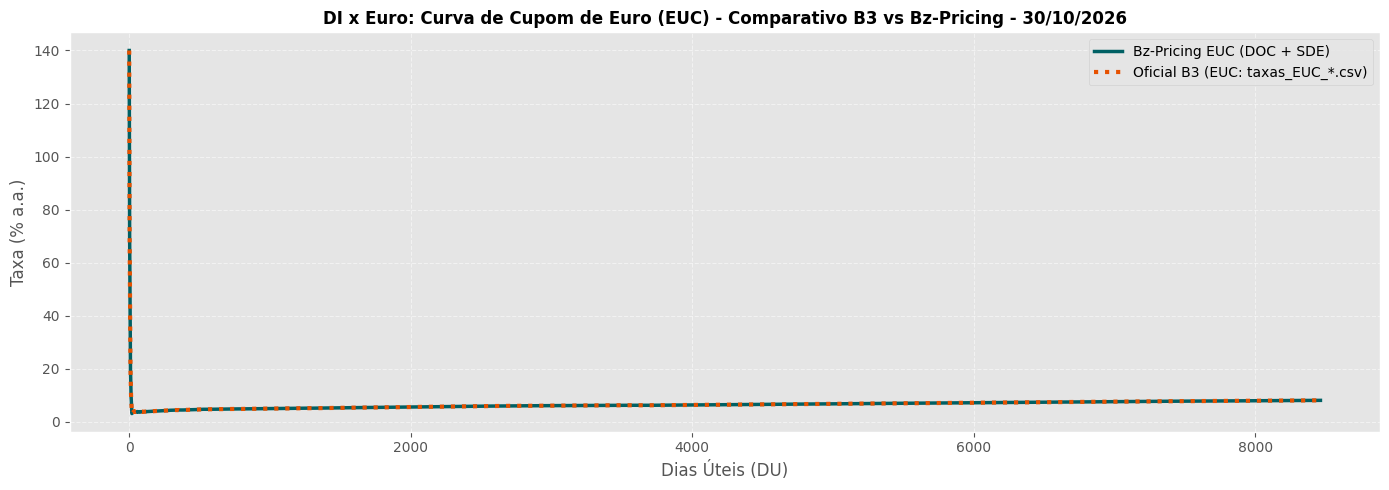

In [16]:
# Curva de Cupom de Euro (EUC) vs Oficial B3
euc_calc_rates = [curve_euc.get_rate(row['day252'], row['day360']) * 100 for _, row in df_b3_euc.iterrows()]

plt.figure(figsize=(14, 5))
plt.plot(df_b3_euc['day252'], euc_calc_rates, label='Bz-Pricing EUC (DOC + SDE)', color='#006064', linewidth=2.5)
plt.plot(df_b3_euc['day252'], df_b3_euc['rate'], ':', label='Oficial B3 (EUC: taxas_EUC_*.csv)', color='#E65100', linewidth=3.0)
plt.title(f'DI x Euro: Curva de Cupom de Euro (EUC) - Comparativo B3 vs Bz-Pricing - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

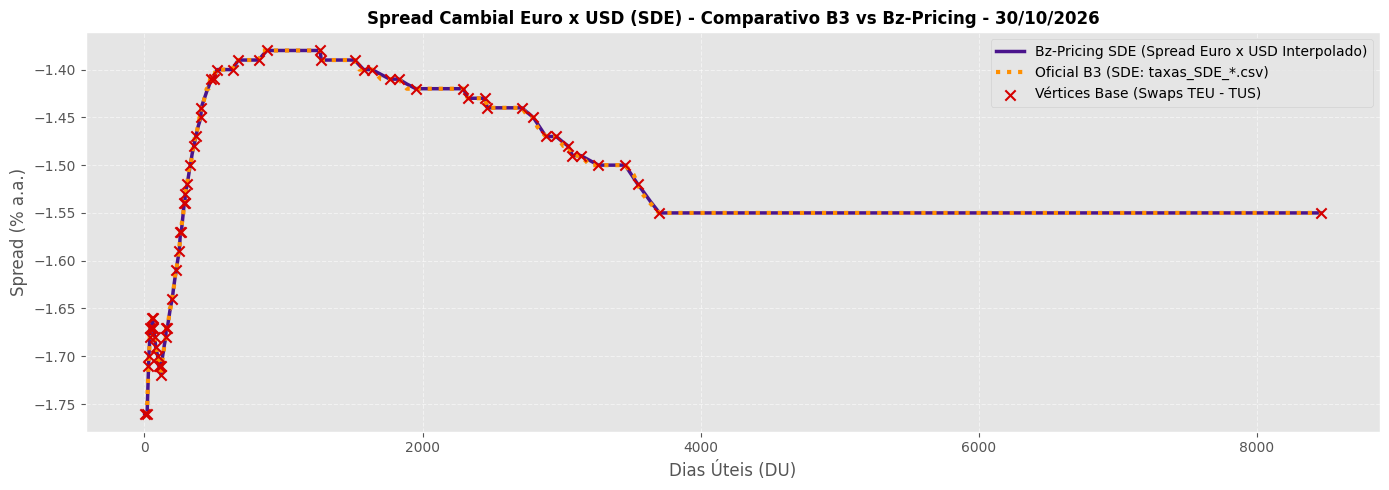

In [17]:
# Curva de Spread Libor Euro x Dólar (SDE) vs Oficial B3
sde_calc_rates = [curve_sde.get_rate(row['day252'], row['day360']) * 100 for _, row in df_b3_sde.iterrows()]

plt.figure(figsize=(14, 5))
plt.plot(df_b3_sde['day252'], sde_calc_rates, label='Bz-Pricing SDE (Spread Euro x USD Interpolado)', color='#4A148C', linewidth=2.5)
plt.plot(df_b3_sde['day252'], df_b3_sde['rate'], ':', label='Oficial B3 (SDE: taxas_SDE_*.csv)', color='#FF8F00', linewidth=3.0)
# Vértices base capturados do provedor externo (Swaps TEU - TUS)
plt.scatter(curve_sde.t_nodes, curve_sde.y_nodes * 100, color='#D50000', marker='x', s=55, label='Vértices Base (Swaps TEU - TUS)', zorder=5)
plt.title(f'Spread Cambial Euro x USD (SDE) - Comparativo B3 vs Bz-Pricing - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Spread (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


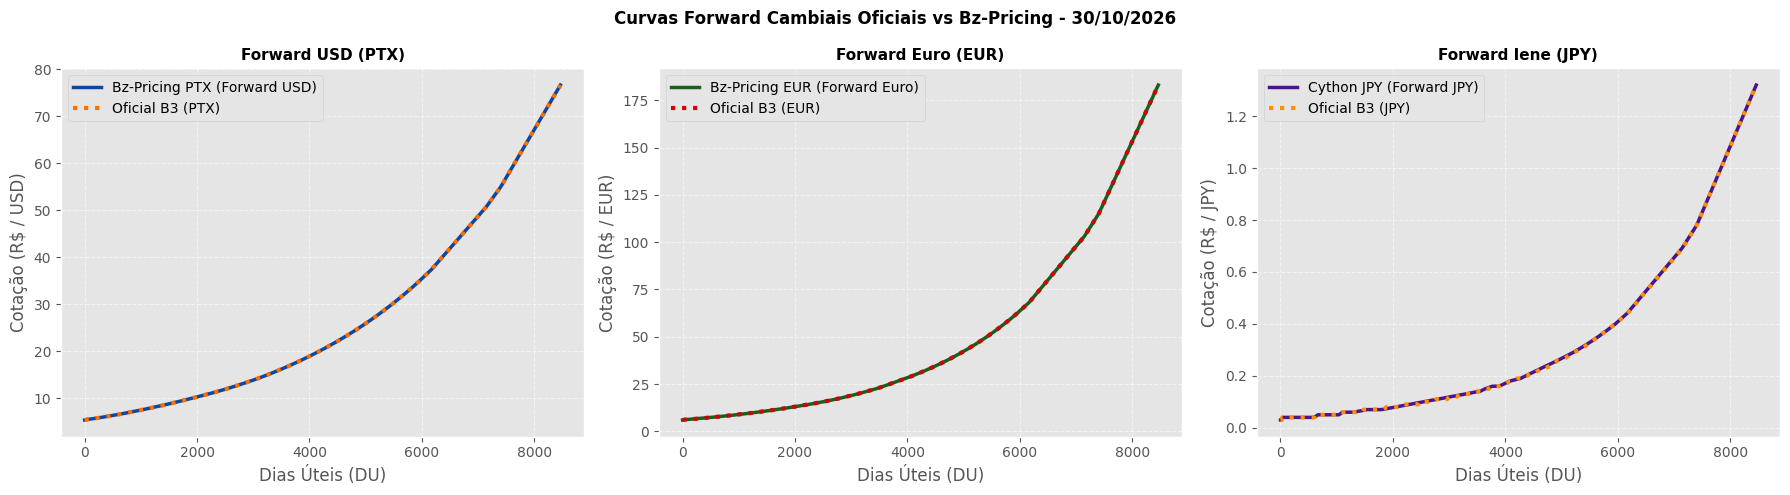

In [18]:
# Curvas Forward de Moedas: PTX (USD), EUR e JPY
fig, (ax_fx1, ax_fx2, ax_fx3) = plt.subplots(1, 3, figsize=(18, 5))

# Subgráfico A: Dólar (PTX)
ax_fx1.plot(df_b3_ptx['day252'], [curve_ptx.get_rate(row['day252'], row['day360']) for _, row in df_b3_ptx.iterrows()], 
            label='Bz-Pricing PTX (Forward USD)', color='#0D47A1', linewidth=2.5)
ax_fx1.plot(df_b3_ptx['day252'], df_b3_ptx['rate'], ':', 
            label='Oficial B3 (PTX)', color='#FF6F00', linewidth=3.0)
ax_fx1.set_title('Forward USD (PTX)', fontsize=11, fontweight='bold')
ax_fx1.set_xlabel('Dias Úteis (DU)')
ax_fx1.set_ylabel('Cotação (R$ / USD)')
ax_fx1.grid(True, linestyle='--', alpha=0.5)
ax_fx1.legend()

# Subgráfico B: Euro (EUR)
ax_fx2.plot(df_b3_eur['day252'], [curve_eur.get_rate(row['day252'], row['day360']) for _, row in df_b3_eur.iterrows()], 
            label='Bz-Pricing EUR (Forward Euro)', color='#1B5E20', linewidth=2.5)
ax_fx2.plot(df_b3_eur['day252'], df_b3_eur['rate'], ':', 
            label='Oficial B3 (EUR)', color='#D50000', linewidth=3.0)
ax_fx2.set_title('Forward Euro (EUR)', fontsize=11, fontweight='bold')
ax_fx2.set_xlabel('Dias Úteis (DU)')
ax_fx2.set_ylabel('Cotação (R$ / EUR)')
ax_fx2.grid(True, linestyle='--', alpha=0.5)
ax_fx2.legend()

# Subgráfico C: Iene Japonês (JPY)
ax_fx3.plot(df_b3_jpy['day252'], [curve_jpy.get_rate(row['day252'], row['day360']) for _, row in df_b3_jpy.iterrows()], 
            label='Cython JPY (Forward JPY)', color='#4A148C', linewidth=2.5)
ax_fx3.plot(df_b3_jpy['day252'], df_b3_jpy['rate'], ':', 
            label='Oficial B3 (JPY)', color='#FF8F00', linewidth=3.0)
ax_fx3.set_title('Forward Iene (JPY)', fontsize=11, fontweight='bold')
ax_fx3.set_xlabel('Dias Úteis (DU)')
ax_fx3.set_ylabel('Cotação (R$ / JPY)')
ax_fx3.grid(True, linestyle='--', alpha=0.5)
ax_fx3.legend()

fig.suptitle(f'Curvas Forward Cambiais Oficiais vs Bz-Pricing - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Convenções de Mercado Cambial (B3):
- **DOL**: Convenção Linear ACT/360 nos contratos DDI com interpolação Flat Forward 252 Linear.
- **SDE**: Diferença analítica entre ZEU (ESTR OIS) e ZUS (SOFR OIS).


## 7. Curvas Internacionais Offshore: SOFR, ESTR e F-TIIE
- **SOFR:** Comparação entre a Curva Forward de Futuros B3 (`SFR`) e a Curva Zero Cupom de Swaps (`ZUS`/`LIB`);
- **ESTR:** Futuros de ESTR B3 (`EST`) ancorados no overnight do ECB;
- **F-TIIE:** Futuros de TIIE B3 (`TIE`) e Curva Zero Cupom (`ZMX`).


Baixando SOFR: https://markets.newyorkfed.org/api/rates/secured/sofr/search.json?startDate=2026-10-20&endDate=2026-10-30


D:\projects\bz_pricing\.venv\lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'markets.newyorkfed.org'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


Arquivo de taxas referenciais (LIB - 20261030) já existe em: ../dados/b3\taxas_LIB_20261030.csv. Use force=True para baixar novamente.


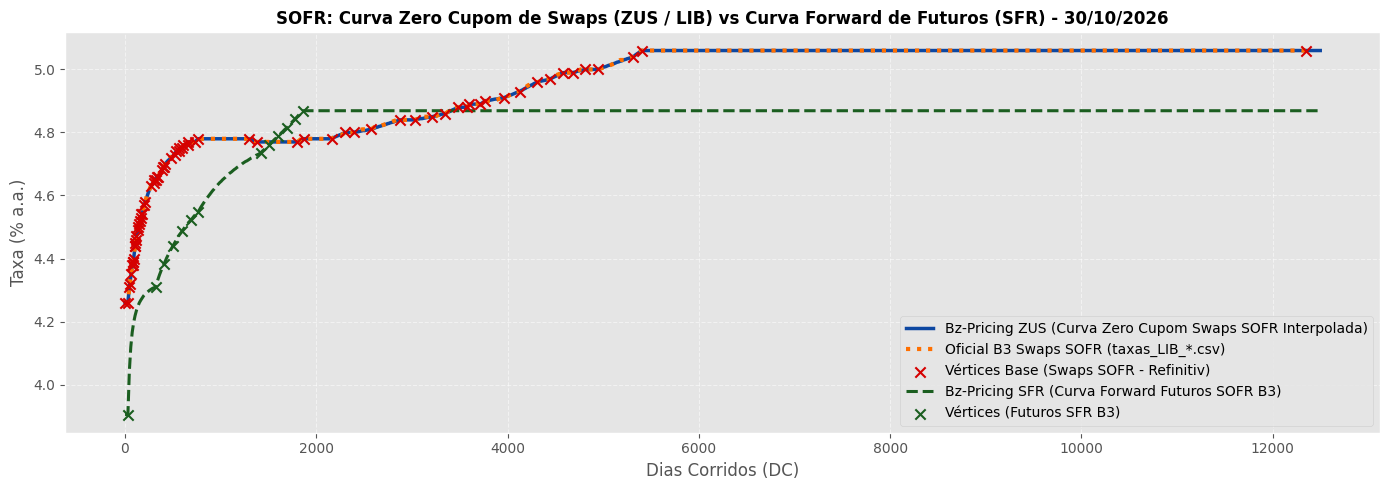

In [19]:
# Carrega curvas de SOFR
curve_zus = manager.get_curve('ZUS', base_date)
curve_sfr = manager.get_curve('SFR', base_date)
df_b3_sofr = pd.read_csv(scraper.download_taxas_referenciais(produto='LIB', data=base_date), sep=';')

dc_eval = np.arange(1, 12500, 15)

plt.figure(figsize=(14, 5))
plt.plot(dc_eval, [curve_zus.get_rate(dc) * 100 for dc in dc_eval], 
         label='Bz-Pricing ZUS (Curva Zero Cupom Swaps SOFR Interpolada)', color='#0D47A1', linewidth=2.5)
plt.plot(df_b3_sofr['day360'], df_b3_sofr['rate'], ':', 
         label='Oficial B3 Swaps SOFR (taxas_LIB_*.csv)', color='#FF6F00', linewidth=3.0)
# Vértices base de Swaps SOFR (LSEG/Refinitiv)
plt.scatter(curve_zus.t_nodes, curve_zus.y_nodes * 100, color='#D50000', marker='x', s=55, 
            label='Vértices Base (Swaps SOFR - Refinitiv)', zorder=5)

plt.plot(dc_eval[:12500], [curve_sfr.get_rate(dc) * 100 for dc in dc_eval[:12500]], '--', 
         label='Bz-Pricing SFR (Curva Forward Futuros SOFR B3)', color='#1B5E20', linewidth=2.2)
# Vértices dos Futuros SFR negociados na B3
plt.scatter(curve_sfr.t_nodes, curve_sfr.y_nodes * 100, color='#1B5E20', marker='x', s=55, 
            label='Vértices (Futuros SFR B3)', zorder=5)

plt.title(f'SOFR: Curva Zero Cupom de Swaps (ZUS / LIB) vs Curva Forward de Futuros (SFR) - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Corridos (DC)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


Baixando ESTR: https://data-api.ecb.europa.eu/service/data/EST/B.EU000A2X2A25.WT?lastNObservations=1&format=jsondata


D:\projects\bz_pricing\.venv\lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'data-api.ecb.europa.eu'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


Baixando ESTR: https://data-api.ecb.europa.eu/service/data/EST/B.EU000A2X2A25.WT?lastNObservations=1&format=jsondata


D:\projects\bz_pricing\.venv\lib\site-packages\urllib3\connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'data-api.ecb.europa.eu'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


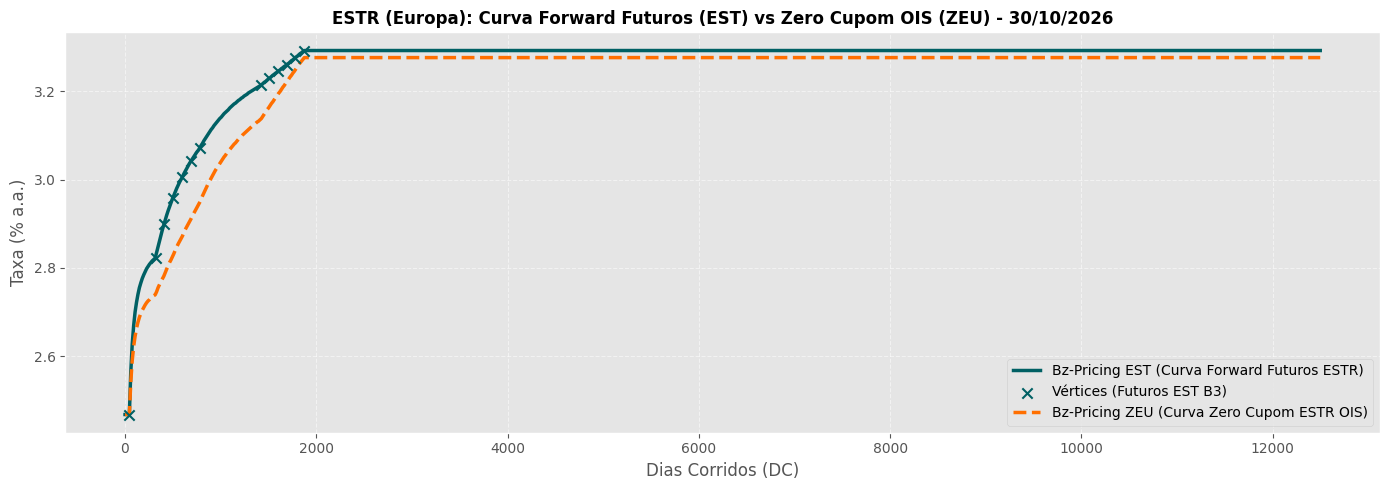

In [20]:
# Carrega curvas ESTR (Europa) e TIIE (México)
curve_est = manager.get_curve('EST', base_date)
curve_zeu = manager.get_curve('ZEU', base_date)
curve_tie = manager.get_curve('TIE', base_date)
curve_zmx = manager.get_curve('ZMX', base_date)

# ESTR (Euro)
plt.figure(figsize=(14, 5))
plt.plot(dc_eval, [curve_est.get_rate(dc) * 100 for dc in dc_eval], 
         label='Bz-Pricing EST (Curva Forward Futuros ESTR)', color='#006064', linewidth=2.5)
plt.scatter(curve_est.t_nodes, curve_est.y_nodes * 100, color='#006064', marker='x', s=55, 
            label='Vértices (Futuros EST B3)', zorder=5)

plt.plot(dc_eval, [curve_zeu.get_rate(dc) * 100 for dc in dc_eval], '--', 
         label='Bz-Pricing ZEU (Curva Zero Cupom ESTR OIS)', color='#FF6F00', linewidth=2.5)
plt.title(f'ESTR (Europa): Curva Forward Futuros (EST) vs Zero Cupom OIS (ZEU) - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Corridos (DC)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


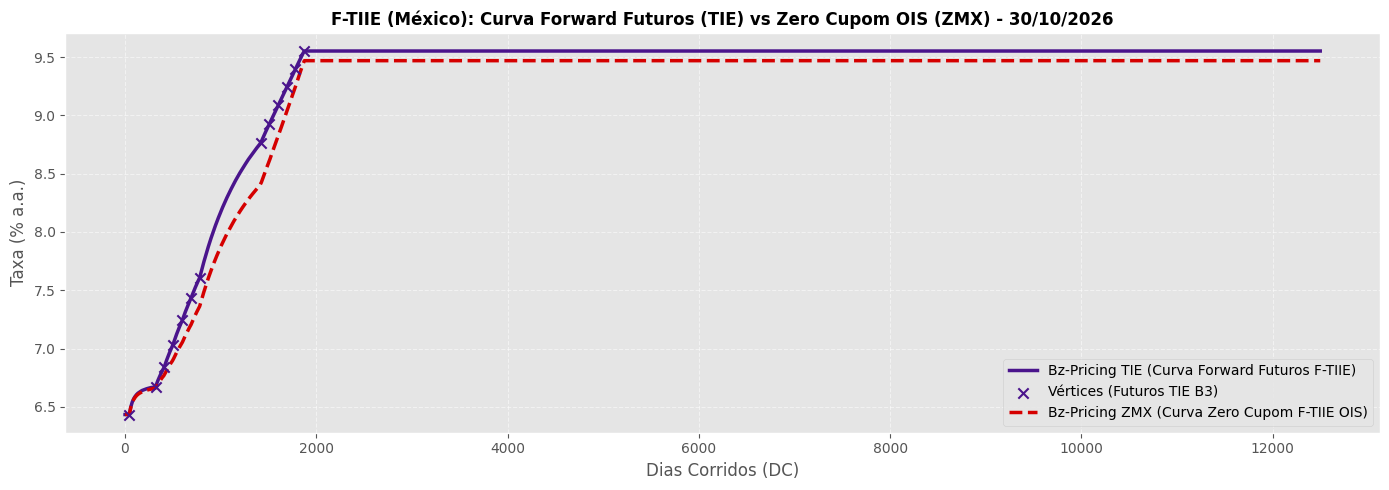

In [21]:
# F-TIIE (México)
plt.figure(figsize=(14, 5))
plt.plot(dc_eval, [curve_tie.get_rate(dc) * 100 for dc in dc_eval], 
         label='Bz-Pricing TIE (Curva Forward Futuros F-TIIE)', color='#4A148C', linewidth=2.5)
plt.scatter(curve_tie.t_nodes, curve_tie.y_nodes * 100, color='#4A148C', marker='x', s=55, 
            label='Vértices (Futuros TIE B3)', zorder=5)

plt.plot(dc_eval, [curve_zmx.get_rate(dc) * 100 for dc in dc_eval], '--', 
         label='Bz-Pricing ZMX (Curva Zero Cupom F-TIIE OIS)', color='#D50000', linewidth=2.5)
plt.title(f'F-TIIE (México): Curva Forward Futuros (TIE) vs Zero Cupom OIS (ZMX) - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Corridos (DC)')
plt.ylabel('Taxa (% a.a.)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


## 8. Curvas de Índices de Ações, Custo de Carrego e Futuros de Ações
Comparações ponto a ponto com os arquivos oficiais da B3:
- **INP:** Preços futuros do Índice Bovespa comparado com `taxas_INP_*.csv` e contratos `IND`;
- **BRP:** Preços futuros do Índice IBrX-50 comparado com `taxas_BRP_*.csv` e contratos `BRI`;
- **CYI:** Custo de Carrego / Convenience Yield implícito do Ibovespa;
- **Futuros de Ações Individuais (PETR4, VALE3):** Estrutura a termo e dividendo implícito anualizado.


Arquivo de taxas referenciais (INP - 20261030) já existe em: ../dados/b3\taxas_INP_20261030.csv. Use force=True para baixar novamente.
Arquivo de taxas referenciais (BRP - 20261030) já existe em: ../dados/b3\taxas_BRP_20261030.csv. Use force=True para baixar novamente.


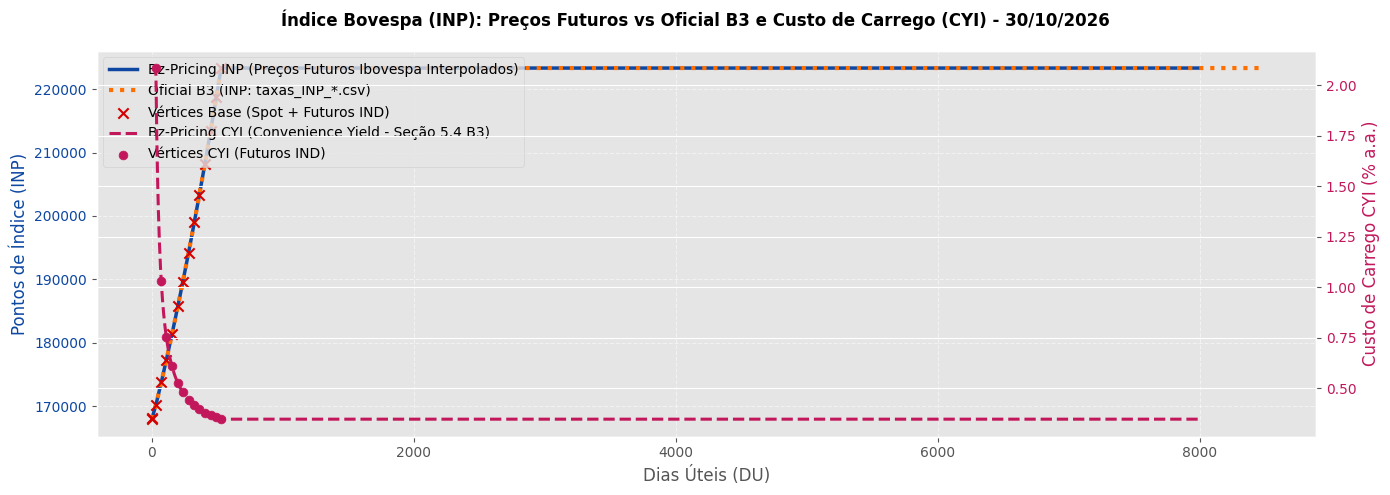

In [22]:
# Carrega curvas calculadas pelo modelo
curve_inp = manager.get_curve('INP', base_date)
curve_cyi = manager.get_curve('CYI', base_date)
curve_brp = manager.get_curve('BRP', base_date)

# Carrega curvas oficiais da B3
b3_inp_path = scraper.download_taxas_referenciais(produto='INP', data=base_date)
b3_brp_path = scraper.download_taxas_referenciais(produto='BRP', data=base_date)
df_b3_inp = pd.read_csv(b3_inp_path, sep=';')
df_b3_brp = pd.read_csv(b3_brp_path, sep=';')

# Contratos futuros reais de IND e BRI negociados na B3 (SPRD)
df_ind = loader.get_curve_instruments(base_date, asst='IND')
du_ind = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_ind['XprtnDt']]
pts_ind = df_ind['AdjstdQt'].values

df_bri = loader.get_curve_instruments(base_date, asst='BRI')
du_bri = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_bri['XprtnDt']]
pts_bri = df_bri['AdjstdQt'].values

dus_eval_eq = np.arange(1, 8000, 2)

# Gráfico Índice Ibovespa Futuros (INP) vs Oficial B3 e Convenience Yield (CYI)
fig, ax1 = plt.subplots(figsize=(14, 5))
color1 = '#0D47A1'
ax1.set_xlabel('Dias Úteis (DU)')
ax1.set_ylabel('Pontos de Índice (INP)', color=color1)
ax1.plot(dus_eval_eq, [curve_inp.get_rate(du) for du in dus_eval_eq], 
         label='Bz-Pricing INP (Preços Futuros Ibovespa Interpolados)', color=color1, linewidth=2.5)
ax1.plot(df_b3_inp['day252'], df_b3_inp['rate'], ':', 
         label='Oficial B3 (INP: taxas_INP_*.csv)', color='#FF6F00', linewidth=3.0)
ax1.scatter(curve_inp.t_nodes, [curve_inp.get_rate(t) for t in curve_inp.t_nodes], 
            color='#D50000', marker='x', s=55, zorder=5, label='Vértices Base (Spot + Futuros IND)')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color2 = '#C2185B'
dus_eval_cyi = np.arange(2, 8000, 2)
ax2.set_ylabel('Custo de Carrego CYI (% a.a.)', color=color2)
ax2.plot(dus_eval_cyi, [curve_cyi.get_rate(du) * 100 for du in dus_eval_cyi], '--', 
         label='Bz-Pricing CYI (Convenience Yield)', color=color2, linewidth=2.2)
ax2.scatter(curve_cyi.t_nodes, [curve_cyi.get_rate(t) * 100 for t in curve_cyi.t_nodes], 
            color=color2, marker='o', s=40, zorder=5, label='Vértices CYI (Futuros IND)')
ax2.tick_params(axis='y', labelcolor=color2)

fig.suptitle(f'Índice Bovespa (INP): Preços Futuros vs Oficial B3 e Custo de Carrego (CYI) - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout()
plt.show()


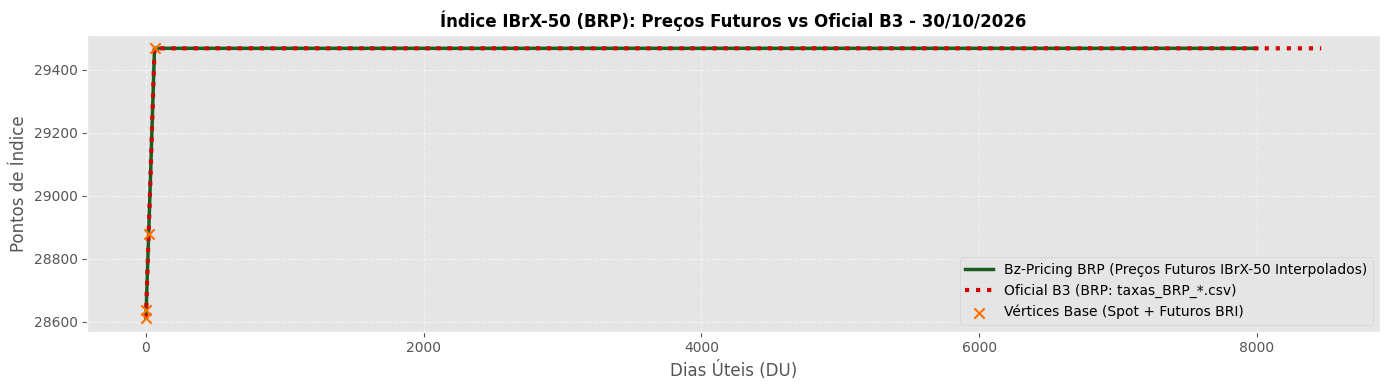

In [23]:
# Índice IBrX-50 Futuros (BRP) vs Oficial B3
plt.figure(figsize=(14, 4))
plt.plot(dus_eval_eq, [curve_brp.get_rate(du) for du in dus_eval_eq], 
         label='Bz-Pricing BRP (Preços Futuros IBrX-50 Interpolados)', color='#1B5E20', linewidth=2.5)
plt.plot(df_b3_brp['day252'], df_b3_brp['rate'], ':', 
         label='Oficial B3 (BRP: taxas_BRP_*.csv)', color='#D50000', linewidth=3.0)
plt.scatter(curve_brp.t_nodes, [curve_brp.get_rate(t) for t in curve_brp.t_nodes], 
            color='#FF6F00', marker='x', s=55, zorder=5, label='Vértices Base (Spot + Futuros BRI)')
plt.title(f'Índice IBrX-50 (BRP): Preços Futuros vs Oficial B3 - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Pontos de Índice')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


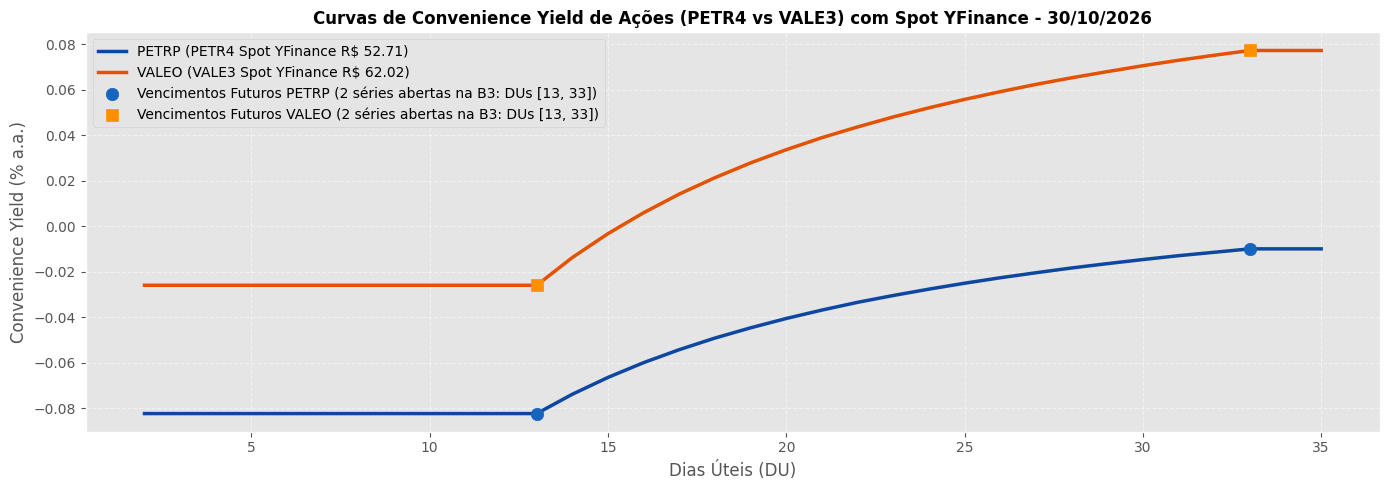

Cotações Spot Yahoo Finance: PETR4 = R$ 52.71 | VALE3 = R$ 62.02
Vencimento Futuro (DU=13): PETRP CY = -0.08% a.a. | VALEO CY = -0.03% a.a.
Vencimento Futuro (DU=33): PETRP CY = -0.01% a.a. | VALEO CY = 0.08% a.a.


In [24]:
# Futuros de Ações e Convenience Yield (PETR4 vs VALE3) via Yahoo Finance
try:
    spot_petr = manager.get_stock_spot('PETRP', base_date)
    spot_vale = manager.get_stock_spot('VALEO', base_date)

    curve_petr_fut, curve_petr_cy = manager.get_stock_future_curve('PETRP', base_date, spot_price=spot_petr)
    curve_vale_fut, curve_vale_cy = manager.get_stock_future_curve('VALEO', base_date, spot_price=spot_vale)

    # Extrai dinamicamente todos os vencimentos futuros disponíveis na curva (excluindo Spot DU=1 e âncora DU=2)
    dus_petr_vcts = [int(t) for t in curve_petr_fut.t_nodes if t > 2.0]
    dus_vale_vcts = [int(t) for t in curve_vale_fut.t_nodes if t > 2.0]
    max_du_stock = max(max(dus_petr_vcts), max(dus_vale_vcts))
    dus_stocks = np.arange(2, max_du_stock + 3, 1)

    plt.figure(figsize=(14, 5))
    plt.plot(dus_stocks, [curve_petr_cy.get_rate(du) * 100 for du in dus_stocks], 
             label=f'PETRP (PETR4 Spot YFinance R$ {spot_petr:.2f})', color='#0D47A1', linewidth=2.5)
    plt.plot(dus_stocks, [curve_vale_cy.get_rate(du) * 100 for du in dus_stocks], 
             label=f'VALEO (VALE3 Spot YFinance R$ {spot_vale:.2f})', color='#E65100', linewidth=2.5)
    
    plt.scatter(dus_petr_vcts, [curve_petr_cy.get_rate(du) * 100 for du in dus_petr_vcts], 
                color='#1565C0', s=80, zorder=5, label=f'Vencimentos Futuros PETRP ({len(dus_petr_vcts)} séries abertas na B3: DUs {dus_petr_vcts})')
    plt.scatter(dus_vale_vcts, [curve_vale_cy.get_rate(du) * 100 for du in dus_vale_vcts], 
                color='#FF8F00', marker='s', s=80, zorder=5, label=f'Vencimentos Futuros VALEO ({len(dus_vale_vcts)} séries abertas na B3: DUs {dus_vale_vcts})')

    plt.title(f'Curvas de Convenience Yield de Ações (PETR4 vs VALE3) com Spot YFinance - {base_date.strftime("%d/%m/%Y")}', fontsize=12, fontweight='bold')
    plt.xlabel('Dias Úteis (DU)')
    plt.ylabel('Convenience Yield (% a.a.)')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Cotações Spot Yahoo Finance: PETR4 = R$ {spot_petr:.2f} | VALE3 = R$ {spot_vale:.2f}")
    for du_v in dus_petr_vcts:
        print(f"Vencimento Futuro (DU={du_v}): PETRP CY = {curve_petr_cy.get_rate(du_v)*100:.2f}% a.a. | VALEO CY = {curve_vale_cy.get_rate(du_v)*100:.2f}% a.a.")
except Exception as e:
    print(f'Nota para Futuros de Ações: {e}')